# Landmark — Direct Conditioning

Input: raw map + UDLR legal-transition channels.

The map encoder is exactly one 1×1 projection to 16 latent channels. No spatial CNN is used before the Conditional UNet.


In [1]:
%pip install tqdm


[notice] A new release of pip is available: 24.0 -> 26.2.1
[notice] To update, run: python -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
import os
import glob
import json
import random
import math
from collections import deque

import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, random_split

from tqdm import tqdm

In [3]:
DATASET_DIR = "dataset"

IMAGE_SIZE = 64

BATCH_SIZE = 32
NUM_EPOCHS = 100
LEARNING_RATE = 2e-4

TIMESTEPS = 500

RAW_MAP_CHANNELS = 3

# Four global topological landmark channels.
# Keeping this at 4 makes the conditioning dimensionality exactly
# match the 7-channel Directional experiment:
#   3 raw + 4 landmark = 7 total channels.
LANDMARK_CHANNELS = 4
MAP_CHANNELS = RAW_MAP_CHANNELS + LANDMARK_CHANNELS

LATENT_CHANNELS = 16
BASE_CHANNELS = 64
TRAIN_RATIO = 0.9

NUM_WORKERS = 4
PREFETCH_FACTOR = 4
PERSISTENT_WORKERS = True

# ------------------------------------------------------------
# Matched-randomness seeds
# ------------------------------------------------------------
# These are intentionally identical to the matched Directional run.
SEED = 42
SPLIT_SEED = 42
DATALOADER_SEED = 43
MAP_ENCODER_SEED = 44
UNET_SEED = 45
TRAIN_TIMESTEP_SEED = 46
TRAIN_NOISE_SEED = 47
VAL_TIMESTEP_SEED = 48
VAL_NOISE_SEED = 49
EVAL_SEED = 2026

PATH_WEIGHT = 5.0

# ------------------------------------------------------------
# Landmark representation
# ------------------------------------------------------------
# Fixed reference locations in normalized map space.
# For a 64x64 map these correspond approximately to:
# (16,16), (16,48), (48,16), (48,48).
#
# IMPORTANT:
# These are NOT start/goal dependent and use no ground-truth path.
# If a reference location is blocked, the nearest free cell is used.
LANDMARK_FRACTIONS = (
    (0.25, 0.25),
    (0.25, 0.75),
    (0.75, 0.25),
    (0.75, 0.75),
)

# Geodesic distance is converted to a smooth proximity field:
# exp(-d / tau).  Obstacles/unreachable cells receive 0.
LANDMARK_TAU = 16.0

# Precomputed landmark channels are cached once on disk so BFS is not
# repeated during every epoch.
LANDMARK_CACHE_DIR = "cache_topological_landmark_4ch"

CHECKPOINT_DIR = (
    "checkpoints_TOPOLOGICAL_LANDMARK4_DIRECT"
    "_x0_path_weighted"
)

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# ------------------------------------------------------------
# Deterministic CUDA / cuDNN behaviour
# ------------------------------------------------------------
os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"
torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True
torch.use_deterministic_algorithms(True, warn_only=True)

print("Device:", DEVICE)
print("Experiment:", "Topological Landmark K=4 Direct — Large U-Net")
print(
    "Conditioning:",
    "raw map + 4 goal-independent geodesic landmark proximity channels",
)
print("Map channels:", MAP_CHANNELS)
print("Base channels:", BASE_CHANNELS)
print("Timesteps:", TIMESTEPS)


Device: cuda
Experiment: Topological Landmark K=4 Direct — Large U-Net
Conditioning: raw map + 4 goal-independent geodesic landmark proximity channels
Map channels: 7
Base channels: 64
Timesteps: 500


In [4]:
def nearest_free_cell(free, target_y, target_x):
    """
    Return the free cell nearest to a fixed reference coordinate.

    The search is deterministic.  It does not use start, goal, or path.
    """
    H, W = free.shape

    target_y = int(np.clip(target_y, 0, H - 1))
    target_x = int(np.clip(target_x, 0, W - 1))

    if free[target_y, target_x]:
        return target_y, target_x

    visited = np.zeros((H, W), dtype=bool)
    queue = deque([(target_y, target_x)])
    visited[target_y, target_x] = True

    # Fixed order for reproducibility.
    directions = [
        (-1, 0),
        (1, 0),
        (0, -1),
        (0, 1),
    ]

    while queue:
        y, x = queue.popleft()

        for dy, dx in directions:
            ny = y + dy
            nx = x + dx

            if (
                0 <= ny < H
                and 0 <= nx < W
                and not visited[ny, nx]
            ):
                if free[ny, nx]:
                    return ny, nx

                visited[ny, nx] = True
                queue.append((ny, nx))

    raise RuntimeError("Map contains no free cell.")


def geodesic_distance_map(free, source):
    """
    4-neighbour shortest-path distance from one landmark to every
    reachable free cell.

    This is a global navigational-topology quantity:
    two cells can be close in image coordinates but far in this map
    when a wall forces a long detour.
    """
    H, W = free.shape

    distances = np.full(
        (H, W),
        np.inf,
        dtype=np.float32,
    )

    sy, sx = source
    distances[sy, sx] = 0.0

    queue = deque([(sy, sx)])

    directions = [
        (-1, 0),
        (1, 0),
        (0, -1),
        (0, 1),
    ]

    while queue:
        y, x = queue.popleft()
        next_distance = distances[y, x] + 1.0

        for dy, dx in directions:
            ny = y + dy
            nx = x + dx

            if (
                0 <= ny < H
                and 0 <= nx < W
                and free[ny, nx]
                and not np.isfinite(distances[ny, nx])
            ):
                distances[ny, nx] = next_distance
                queue.append((ny, nx))

    return distances


def build_topological_landmark_channels(obstacle_map):
    """
    Build four goal-independent global topological channels.

    Step 1:
        Place four fixed reference locations at the quarter points
        of the map. If a reference lies inside an obstacle, move it
        deterministically to the nearest free cell.

    Step 2:
        Compute 4-neighbour geodesic distance through FREE SPACE from
        each landmark to every cell.

    Step 3:
        Convert distance to a bounded proximity field:

            phi_k(s) = exp(-d_geo(s, L_k) / LANDMARK_TAU)

        Obstacles and cells unreachable from a landmark are 0.

    Output:
        [4, H, W] float32 tensor.

    The representation depends only on obstacle topology.
    It does NOT use start, goal, or the A* target path.
    """
    free = obstacle_map <= 0.5
    H, W = free.shape

    channels = []

    for fy, fx in LANDMARK_FRACTIONS:
        target_y = int(round(fy * (H - 1)))
        target_x = int(round(fx * (W - 1)))

        landmark = nearest_free_cell(
            free,
            target_y,
            target_x,
        )

        distance = geodesic_distance_map(
            free,
            landmark,
        )

        proximity = np.zeros(
            (H, W),
            dtype=np.float32,
        )

        reachable = (
            free
            & np.isfinite(distance)
        )

        proximity[reachable] = np.exp(
            -distance[reachable]
            / float(LANDMARK_TAU)
        ).astype(np.float32)

        channels.append(proximity)

    return np.stack(
        channels,
        axis=0,
    ).astype(np.float32, copy=False)


def landmark_cache_path(filepath):
    stem = os.path.splitext(
        os.path.basename(filepath)
    )[0]

    return os.path.join(
        LANDMARK_CACHE_DIR,
        stem + "_landmark4.npy",
    )


def prepare_landmark_cache(dataset_dir):
    """
    Compute each sample's 4 landmark channels once.

    Cache is float16 on disk to reduce storage. It is converted back
    to float32 when loaded for training.

    This preprocessing does not change the training data split or any
    model randomness.
    """
    files = sorted(
        glob.glob(
            os.path.join(dataset_dir, "pair_*.npz")
        )
    )

    if len(files) == 0:
        raise RuntimeError(
            f"No .npz files found in {dataset_dir}"
        )

    os.makedirs(
        LANDMARK_CACHE_DIR,
        exist_ok=True,
    )

    missing = [
        filepath
        for filepath in files
        if not os.path.exists(
            landmark_cache_path(filepath)
        )
    ]

    print(
        f"Landmark cache: {len(files) - len(missing)}/{len(files)} ready."
    )

    if len(missing) == 0:
        return

    print(
        f"Precomputing {len(missing)} topological landmark maps..."
    )

    for filepath in tqdm(
        missing,
        desc="Landmark preprocessing",
        dynamic_ncols=True,
    ):
        with np.load(filepath) as data:
            raw_map = np.asarray(
                data["map"],
                dtype=np.float32,
            )

        obstacle = raw_map[0]

        landmark_channels = (
            build_topological_landmark_channels(
                obstacle
            )
        )

        np.save(
            landmark_cache_path(filepath),
            landmark_channels.astype(np.float16),
            allow_pickle=False,
        )

    print("Landmark cache complete.")


# Build once before DataLoader workers are created.
prepare_landmark_cache(DATASET_DIR)


class MazePathDataset(Dataset):

    def __init__(self, dataset_dir):
        self.files = sorted(
            glob.glob(
                os.path.join(dataset_dir, "pair_*.npz")
            )
        )

        if len(self.files) == 0:
            raise RuntimeError(
                f"No .npz files found in {dataset_dir}"
            )

        print(f"Found {len(self.files)} samples.")

    def __len__(self):
        return len(self.files)

    def __getitem__(self, idx):
        filepath = self.files[idx]

        with np.load(filepath) as data:
            raw_map = np.asarray(
                data["map"],
                dtype=np.float32,
            )
            path = np.asarray(
                data["path"],
                dtype=np.float32,
            )

        expected_raw_shape = (
            RAW_MAP_CHANNELS,
            IMAGE_SIZE,
            IMAGE_SIZE,
        )

        if raw_map.shape != expected_raw_shape:
            raise ValueError(
                f"{filepath}: expected raw map shape "
                f"{expected_raw_shape}, got {raw_map.shape}"
            )

        landmark_channels = np.load(
            landmark_cache_path(filepath),
            allow_pickle=False,
        ).astype(np.float32)

        expected_landmark_shape = (
            LANDMARK_CHANNELS,
            IMAGE_SIZE,
            IMAGE_SIZE,
        )

        if landmark_channels.shape != expected_landmark_shape:
            raise ValueError(
                f"{filepath}: expected landmark shape "
                f"{expected_landmark_shape}, "
                f"got {landmark_channels.shape}"
            )

        grid_map = np.concatenate(
            [raw_map, landmark_channels],
            axis=0,
        ).astype(np.float32, copy=False)

        expected_input_shape = (
            MAP_CHANNELS,
            IMAGE_SIZE,
            IMAGE_SIZE,
        )

        if grid_map.shape != expected_input_shape:
            raise ValueError(
                f"{filepath}: expected conditioning shape "
                f"{expected_input_shape}, got {grid_map.shape}"
            )

        grid_map = torch.from_numpy(grid_map)
        path = torch.from_numpy(path)

        # {0,1} -> {-1,1}
        path = path * 2.0 - 1.0

        return {
            "map": grid_map,
            "path": path,
            "sample_index": int(idx),
        }


Landmark cache: 10000/10000 ready.


## Dataset loader

In [5]:
dataset = MazePathDataset(
    dataset_dir=DATASET_DIR
)

train_size = int(
    len(dataset) * TRAIN_RATIO
)
val_size = len(dataset) - train_size

split_generator = torch.Generator().manual_seed(
    SPLIT_SEED
)

train_dataset, val_dataset = random_split(
    dataset,
    [train_size, val_size],
    generator=split_generator,
)

print("Train:", len(train_dataset))
print("Validation:", len(val_dataset))

sample0 = dataset[0]

print("Map shape:", sample0["map"].shape)
print("Path shape:", sample0["path"].shape)

assert sample0["map"].shape == (
    MAP_CHANNELS,
    IMAGE_SIZE,
    IMAGE_SIZE,
)

print(
    "Total conditioning channels:",
    sample0["map"].shape[0],
)

loader_kwargs = dict(
    batch_size=BATCH_SIZE,
    num_workers=NUM_WORKERS,
    pin_memory=True,
)

if NUM_WORKERS > 0:
    loader_kwargs.update(
        persistent_workers=PERSISTENT_WORKERS,
        prefetch_factor=PREFETCH_FACTOR,
    )

# ------------------------------------------------------------
# Matched DataLoader randomness
# ------------------------------------------------------------
# The explicit generator fixes the per-epoch shuffled sample order.
train_loader_generator = torch.Generator().manual_seed(
    DATALOADER_SEED
)

val_loader_generator = torch.Generator().manual_seed(
    DATALOADER_SEED + 1
)


def seed_worker(worker_id):
    """Deterministically seed Python / NumPy inside each worker."""
    worker_seed = (
        DATALOADER_SEED + worker_id
    ) % (2 ** 32)

    random.seed(worker_seed)
    np.random.seed(worker_seed)


train_loader = DataLoader(
    train_dataset,
    shuffle=True,
    generator=train_loader_generator,
    worker_init_fn=seed_worker,
    **loader_kwargs,
)

val_loader = DataLoader(
    val_dataset,
    shuffle=False,
    generator=val_loader_generator,
    worker_init_fn=seed_worker,
    **loader_kwargs,
)

Found 10000 samples.
Train: 9000
Validation: 1000
Map shape: torch.Size([7, 64, 64])
Path shape: torch.Size([1, 64, 64])
Total conditioning channels: 7


Conditioning shape: (7, 64, 64)
Raw channels:       3
Landmark channels:  4
Total channels:     7

This exactly matches the Directional experiment's 7 -> 16 DirectMapEncoder dimensionality.


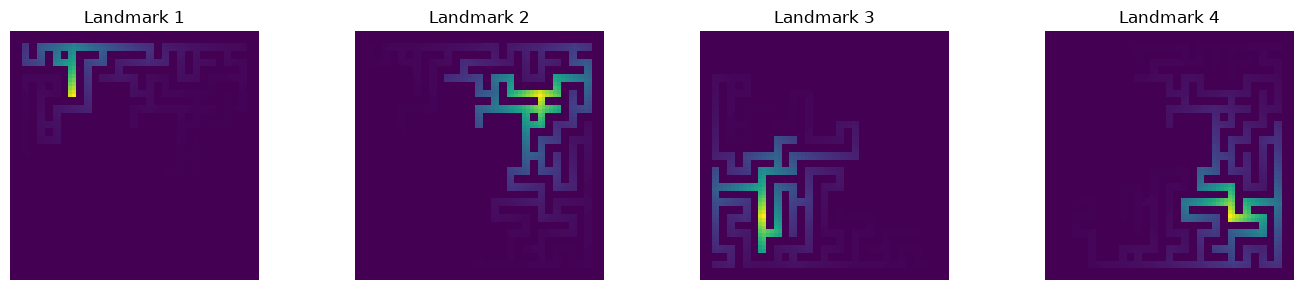

In [6]:
# ------------------------------------------------------------
# Representation sanity check
# ------------------------------------------------------------
sample = dataset[0]
condition = sample["map"]

assert condition.shape == (
    7,
    IMAGE_SIZE,
    IMAGE_SIZE,
)

print("Conditioning shape:", tuple(condition.shape))
print("Raw channels:       3")
print("Landmark channels:  4")
print("Total channels:     7")
print()
print(
    "This exactly matches the Directional experiment's "
    "7 -> 16 DirectMapEncoder dimensionality."
)

# Optional visualization of the four global topological fields.
fig, axes = plt.subplots(
    1,
    LANDMARK_CHANNELS,
    figsize=(14, 3),
)

for k in range(LANDMARK_CHANNELS):
    axes[k].imshow(
        condition[RAW_MAP_CHANNELS + k].numpy(),
        origin="upper",
    )
    axes[k].set_title(f"Landmark {k + 1}")
    axes[k].axis("off")

plt.tight_layout()
plt.show()


## Cognitive Map Encoder

In [7]:
class DirectMapEncoder(nn.Module):
    """
    Direct representation projection only.

    Exactly one 1x1 convolution maps MAP_CHANNELS -> 16.
    There is no spatial feature extractor in the map encoder.
    """

    def __init__(
        self,
        in_channels=MAP_CHANNELS,
        latent_channels=LATENT_CHANNELS,
    ):
        super().__init__()

        self.projection = nn.Conv2d(
            in_channels,
            latent_channels,
            kernel_size=1,
            padding=0,
            bias=True,
        )

    def forward(self, grid_map):
        if grid_map.shape[1] != MAP_CHANNELS:
            raise ValueError(
                f"Expected {MAP_CHANNELS} channels, "
                f"got {grid_map.shape[1]}"
            )
        return self.projection(grid_map)


# Do not let this diagnostic instance advance the global RNG state.
with torch.random.fork_rng(devices=[]):
    torch.manual_seed(MAP_ENCODER_SEED)
    encoder_check = DirectMapEncoder()

encoder_params = sum(
    p.numel()
    for p in encoder_check.parameters()
    if p.requires_grad
)

expected_params = (
    MAP_CHANNELS * LATENT_CHANNELS
    + LATENT_CHANNELS
)

print(
    "Direct encoder parameters:",
    f"{encoder_params:,}",
)
print(
    "Expected parameters:",
    f"{expected_params:,}",
)

assert encoder_params == expected_params

conv_layers = [
    m
    for m in encoder_check.modules()
    if isinstance(m, nn.Conv2d)
]

assert len(conv_layers) == 1
assert conv_layers[0].kernel_size == (1, 1)

Direct encoder parameters: 128
Expected parameters: 128


## Diffusion timestep embedding

In [8]:
class SinusoidalTimeEmbedding(nn.Module):

    def __init__(self, dim):

        super().__init__()

        self.dim = dim

    def forward(self, time):

        device = time.device

        half_dim = self.dim // 2

        embeddings = math.log(
            10000
        ) / (half_dim - 1)

        embeddings = torch.exp(
            torch.arange(
                half_dim,
                device=device
            )
            * -embeddings
        )

        embeddings = (
            time[:, None].float()
            *
            embeddings[None, :]
        )

        embeddings = torch.cat(
            (
                embeddings.sin(),
                embeddings.cos()
            ),
            dim=1
        )

        return embeddings

## UNet Residual Block

In [9]:
class ResBlock(nn.Module):

    def __init__(
        self,
        in_channels,
        out_channels,
        time_dim
    ):

        super().__init__()

        self.conv1 = nn.Conv2d(
            in_channels,
            out_channels,
            kernel_size=3,
            padding=1
        )

        self.norm1 = nn.GroupNorm(
            8,
            out_channels
        )

        self.conv2 = nn.Conv2d(
            out_channels,
            out_channels,
            kernel_size=3,
            padding=1
        )

        self.norm2 = nn.GroupNorm(
            8,
            out_channels
        )

        self.time_mlp = nn.Linear(
            time_dim,
            out_channels
        )

        if in_channels != out_channels:

            self.residual = nn.Conv2d(
                in_channels,
                out_channels,
                kernel_size=1
            )

        else:

            self.residual = nn.Identity()

    def forward(
        self,
        x,
        time_emb
    ):

        residual = self.residual(x)

        h = self.conv1(x)
        h = self.norm1(h)
        h = F.silu(h)

        # --------------------------------
        # timestep information
        # --------------------------------

        time_feature = self.time_mlp(
            time_emb
        )

        time_feature = time_feature[
            :,
            :,
            None,
            None
        ]

        h = h + time_feature

        h = self.conv2(h)
        h = self.norm2(h)
        h = F.silu(h)

        return h + residual

## Conditional UNet

In [10]:
class ConditionalUNet(nn.Module):

    def __init__(
        self,
        map_latent_channels=16,
        base_channels=64,
        time_dim=256
    ):

        super().__init__()

        input_channels = (
            1 + map_latent_channels
        )

        # ========================================
        # Time embedding
        # ========================================

        self.time_embedding = nn.Sequential(

            SinusoidalTimeEmbedding(
                time_dim
            ),

            nn.Linear(
                time_dim,
                time_dim
            ),

            nn.SiLU(),

            nn.Linear(
                time_dim,
                time_dim
            )
        )

        # ========================================
        # Input
        # ========================================

        self.input_conv = nn.Conv2d(
            input_channels,
            base_channels,
            kernel_size=3,
            padding=1
        )

        # ========================================
        # Encoder
        # ========================================

        self.down1 = ResBlock(
            base_channels,
            base_channels,
            time_dim
        )

        self.pool1 = nn.Conv2d(
            base_channels,
            base_channels,
            kernel_size=4,
            stride=2,
            padding=1
        )

        self.down2 = ResBlock(
            base_channels,
            base_channels * 2,
            time_dim
        )

        self.pool2 = nn.Conv2d(
            base_channels * 2,
            base_channels * 2,
            kernel_size=4,
            stride=2,
            padding=1
        )

        # ========================================
        # Bottleneck
        # ========================================

        self.mid1 = ResBlock(
            base_channels * 2,
            base_channels * 4,
            time_dim
        )

        self.mid2 = ResBlock(
            base_channels * 4,
            base_channels * 4,
            time_dim
        )

        # ========================================
        # Decoder
        # ========================================

        self.up2 = nn.ConvTranspose2d(
            base_channels * 4,
            base_channels * 2,
            kernel_size=4,
            stride=2,
            padding=1
        )

        self.up_block2 = ResBlock(
            base_channels * 4,
            base_channels * 2,
            time_dim
        )

        self.up1 = nn.ConvTranspose2d(
            base_channels * 2,
            base_channels,
            kernel_size=4,
            stride=2,
            padding=1
        )

        self.up_block1 = ResBlock(
            base_channels * 2,
            base_channels,
            time_dim
        )

        # ========================================
        # Output
        # ========================================

        self.output = nn.Conv2d(
            base_channels,
            1,
            kernel_size=1
        )

    def forward(
        self,
        x,
        timestep
    ):

        # timestep embedding
        t = self.time_embedding(
            timestep
        )

        # input
        x = self.input_conv(x)

        # ----------------------------------------
        # Down
        # ----------------------------------------

        skip1 = self.down1(
            x,
            t
        )

        x = self.pool1(
            skip1
        )

        skip2 = self.down2(
            x,
            t
        )

        x = self.pool2(
            skip2
        )

        # ----------------------------------------
        # Middle
        # ----------------------------------------

        x = self.mid1(
            x,
            t
        )

        x = self.mid2(
            x,
            t
        )

        # ----------------------------------------
        # Up
        # ----------------------------------------

        x = self.up2(x)

        x = torch.cat(
            [x, skip2],
            dim=1
        )

        x = self.up_block2(
            x,
            t
        )

        x = self.up1(x)

        x = torch.cat(
            [x, skip1],
            dim=1
        )

        x = self.up_block1(
            x,
            t
        )

        return self.output(x)

## DDPM noise schedule

In [11]:
class GaussianDiffusion:

    def __init__(
        self,
        timesteps=1000,
        beta_start=1e-4,
        beta_end=0.02,
        device="cuda"
    ):

        self.timesteps = timesteps
        self.device = device

        # ----------------------------------------
        # Linear beta schedule
        # ----------------------------------------

        self.betas = torch.linspace(
            beta_start,
            beta_end,
            timesteps,
            device=device
        )

        self.alphas = (
            1.0 - self.betas
        )

        self.alpha_cumprod = torch.cumprod(
            self.alphas,
            dim=0
        )

        self.alpha_cumprod_prev = F.pad(
            self.alpha_cumprod[:-1],
            (1, 0),
            value=1.0
        )

        self.sqrt_alpha_cumprod = (
            torch.sqrt(
                self.alpha_cumprod
            )
        )

        self.sqrt_one_minus_alpha_cumprod = (
            torch.sqrt(
                1.0
                -
                self.alpha_cumprod
            )
        )

        self.sqrt_recip_alphas = (
            torch.sqrt(
                1.0 / self.alphas
            )
        )

        # ----------------------------------------
        # Posterior variance
        # ----------------------------------------

        self.posterior_variance = (
            self.betas
            *
            (
                1.0
                -
                self.alpha_cumprod_prev
            )
            /
            (
                1.0
                -
                self.alpha_cumprod
            )
        )

## Helper

In [12]:
def extract(
    values,
    timestep,
    x_shape
):

    batch_size = timestep.shape[0]

    out = values.gather(
        0,
        timestep
    )

    return out.reshape(
        batch_size,
        *((1,) * (len(x_shape) - 1))
    )

## Forward diffusion

In [13]:
def q_sample(
    diffusion,
    x_start,
    timestep,
    noise=None
):

    if noise is None:
        noise = torch.randn_like(
            x_start
        )

    sqrt_alpha_cumprod_t = extract(
        diffusion.sqrt_alpha_cumprod,
        timestep,
        x_start.shape
    )

    sqrt_one_minus_alpha_cumprod_t = (
        extract(
            diffusion.sqrt_one_minus_alpha_cumprod,
            timestep,
            x_start.shape
        )
    )

    noisy_path = (
        sqrt_alpha_cumprod_t
        *
        x_start

        +

        sqrt_one_minus_alpha_cumprod_t
        *
        noise
    )

    return noisy_path, noise

In [14]:
class DiffusionPathPlanner(nn.Module):

    def __init__(
        self,
        latent_channels=LATENT_CHANNELS,
        base_channels=BASE_CHANNELS,
    ):
        super().__init__()

        # ------------------------------------------------------------
        # Matched initialization
        # ------------------------------------------------------------
        # Encoder dimensionality legitimately differs by representation.
        # Its RNG is isolated so that it cannot shift the U-Net RNG stream.
        with torch.random.fork_rng(devices=[]):
            torch.manual_seed(MAP_ENCODER_SEED)
            self.map_encoder = DirectMapEncoder(
                in_channels=MAP_CHANNELS,
                latent_channels=latent_channels,
            )

        # This seed is identical across all four notebooks, so every
        # parameter of the shared downstream U-Net starts identically.
        with torch.random.fork_rng(devices=[]):
            torch.manual_seed(UNET_SEED)
            self.unet = ConditionalUNet(
                map_latent_channels=latent_channels,
                base_channels=base_channels,
            )

    def encode_map(self, grid_map):
        return self.map_encoder(grid_map)

    def predict_x0(
        self,
        noisy_path,
        map_latent,
        timestep,
    ):
        model_input = torch.cat(
            [noisy_path, map_latent],
            dim=1,
        )

        return self.unet(
            model_input,
            timestep,
        )

    def forward(
        self,
        grid_map,
        noisy_path,
        timestep,
    ):
        map_latent = self.encode_map(
            grid_map
        )

        return self.predict_x0(
            noisy_path,
            map_latent,
            timestep,
        )

## Training function

In [15]:
def train_one_epoch(
    model,
    loader,
    optimizer,
    diffusion,
    device,
    timestep_generator,
    noise_generator,
):

    model.train()

    total_loss = 0.0

    progress_bar = tqdm(
        loader,
        desc="Training",
        leave=False
    )

    for batch in progress_bar:

        grid_map = batch["map"].to(
            device,
            non_blocking=True
        )

        path = batch["path"].to(
            device,
            non_blocking=True
        )

        batch_size = path.shape[0]

        # ----------------------------------------
        # Random timestep
        # ----------------------------------------

        timestep = torch.randint(
            0,
            diffusion.timesteps,
            (batch_size,),
            device=device,
            generator=timestep_generator,
        ).long()

        # ----------------------------------------
        # Forward diffusion
        #
        # path = clean x0
        # noisy_path = x_t
        # ----------------------------------------

        noise = torch.randn(
            path.shape,
            device=device,
            dtype=path.dtype,
            generator=noise_generator,
        )

        noisy_path, _ = q_sample(
            diffusion,
            path,
            timestep,
            noise=noise,
        )

        # ----------------------------------------
        # Predict clean x0
        # ----------------------------------------

        predicted_x0 = model(
            grid_map,
            noisy_path,
            timestep
        )

        # ============================================================
        # Weighted x0 reconstruction loss
        # ============================================================

        path_mask = (
            path > 0
        ).float()

        weights = (
            1.0
            +
            (PATH_WEIGHT - 1.0)
            *
            path_mask
        )

        squared_error = (
            predicted_x0
            -
            path
        ).pow(2)

        loss = (
            weights
            *
            squared_error
        ).mean()

        optimizer.zero_grad(
            set_to_none=True
        )

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=1.0
        )

        optimizer.step()

        total_loss += loss.item()

        progress_bar.set_postfix(
            loss=f"{loss.item():.4f}"
        )

    return (
        total_loss
        /
        len(loader)
    )

## Validation function

In [16]:
@torch.no_grad()
def validate(
    model,
    loader,
    diffusion,
    device,
    timestep_generator,
    noise_generator,
):

    model.eval()

    total_loss = 0.0

    for batch in loader:

        grid_map = batch["map"].to(
            device,
            non_blocking=True
        )

        path = batch["path"].to(
            device,
            non_blocking=True
        )

        batch_size = path.shape[0]

        timestep = torch.randint(
            0,
            diffusion.timesteps,
            (batch_size,),
            device=device,
            generator=timestep_generator,
        ).long()

        # ----------------------------------------
        # Forward diffusion
        # ----------------------------------------

        noise = torch.randn(
            path.shape,
            device=device,
            dtype=path.dtype,
            generator=noise_generator,
        )

        noisy_path, _ = q_sample(
            diffusion,
            path,
            timestep,
            noise=noise,
        )

        predicted_x0 = model(
            grid_map,
            noisy_path,
            timestep
        )

        path_mask = (
            path > 0
        ).float()

        weights = (
            1.0
            +
            (PATH_WEIGHT - 1.0)
            *
            path_mask
        )

        squared_error = (
            predicted_x0
            -
            path
        ).pow(2)

        loss = (
            weights
            *
            squared_error
        ).mean()

        total_loss += loss.item()

    return (
        total_loss
        /
        len(loader)
    )

In [15]:
os.makedirs(
    CHECKPOINT_DIR,
    exist_ok=True,
)

model = DiffusionPathPlanner(
    latent_channels=LATENT_CHANNELS,
    base_channels=BASE_CHANNELS,
).to(DEVICE)

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
)

diffusion = GaussianDiffusion(
    timesteps=TIMESTEPS,
    device=DEVICE,
)

def make_device_generator(seed, device):
    """Create a reproducible RNG on the same device as sampled tensors."""
    generator_device = (
        "cuda"
        if device.type == "cuda"
        else "cpu"
    )

    generator = torch.Generator(
        device=generator_device
    )
    generator.manual_seed(seed)
    return generator


train_timestep_generator = make_device_generator(
    TRAIN_TIMESTEP_SEED,
    DEVICE,
)
train_noise_generator = make_device_generator(
    TRAIN_NOISE_SEED,
    DEVICE,
)
val_timestep_generator = make_device_generator(
    VAL_TIMESTEP_SEED,
    DEVICE,
)
val_noise_generator = make_device_generator(
    VAL_NOISE_SEED,
    DEVICE,
)

total_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

print(
    "Total trainable parameters:",
    f"{total_params:,}"
)

Total trainable parameters: 4,355,457


## Full training loop

In [18]:
best_val_loss = float("inf")

train_losses = []
val_losses = []

for epoch in range(
    1,
    NUM_EPOCHS + 1,
):

    print(f"\nEpoch {epoch}/{NUM_EPOCHS}")

    train_loss = train_one_epoch(
        model,
        train_loader,
        optimizer,
        diffusion,
        DEVICE,
        train_timestep_generator,
        train_noise_generator,
    )

    val_loss = validate(
        model,
        val_loader,
        diffusion,
        DEVICE,
        val_timestep_generator,
        val_noise_generator,
    )

    train_losses.append(train_loss)
    val_losses.append(val_loss)

    print(f"Train loss: {train_loss:.6f}")
    print(f"Val loss:   {val_loss:.6f}")

    torch.save(
        {
            "epoch": epoch,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "train_loss": train_loss,
            "val_loss": val_loss,
        },
        os.path.join(
            CHECKPOINT_DIR,
            "latest.pt",
        ),
    )

    if val_loss < best_val_loss:

        best_val_loss = val_loss

        torch.save(
            {
                "epoch": epoch,
                "model_state_dict": model.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "train_loss": train_loss,
                "val_loss": val_loss,
            },
            os.path.join(
                CHECKPOINT_DIR,
                "best.pt",
            ),
        )

        print(
            f"Saved new best model: "
            f"{best_val_loss:.6f}"
        )


Epoch 1/100


Train loss: 0.157080
Val loss:   0.109902
Saved new best model: 0.109902

Epoch 2/100


Train loss: 0.098228
Val loss:   0.091553
Saved new best model: 0.091553

Epoch 3/100


Train loss: 0.080387
Val loss:   0.072293
Saved new best model: 0.072293

Epoch 4/100


Train loss: 0.066907
Val loss:   0.061941
Saved new best model: 0.061941

Epoch 5/100


...

Train loss: 0.008280
Val loss:   0.024517

Epoch 97/100


Train loss: 0.008564
Val loss:   0.023682

Epoch 98/100


Train loss: 0.007473
Val loss:   0.021431

Epoch 99/100


Train loss: 0.008002
Val loss:   0.021525

Epoch 100/100


Train loss: 0.007663
Val loss:   0.021383


## Plot loss curve

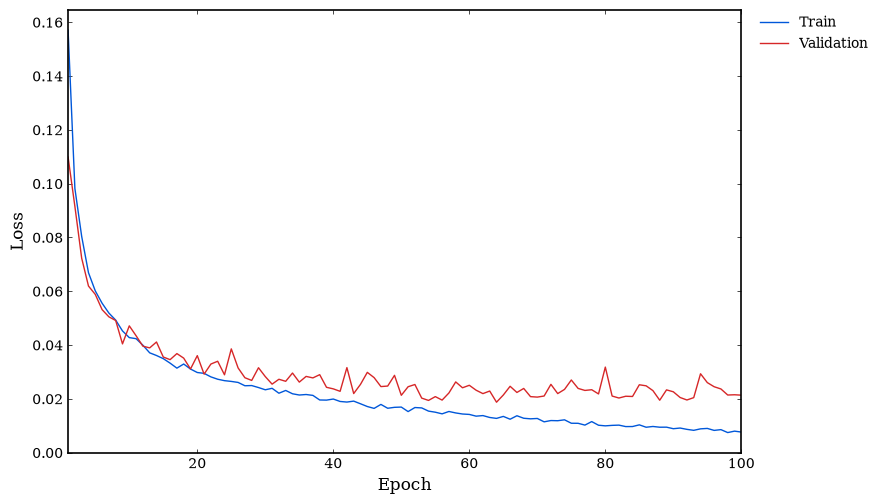

In [19]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import AutoMinorLocator

# ------------------------------------------------------------
# Plot style
# ------------------------------------------------------------
plt.rcParams.update({
    "font.family": "serif",
    "font.size": 12,
    "axes.labelsize": 12,
    "legend.fontsize": 10,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "axes.linewidth": 1.2,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.top": True,
    "ytick.right": True,
    "legend.frameon": False,
    "figure.dpi": 100,
})

# ------------------------------------------------------------
# Prepare data
# ------------------------------------------------------------
train_losses_plot = np.asarray(train_losses, dtype=float)
val_losses_plot = np.asarray(val_losses, dtype=float)

if len(train_losses_plot) != len(val_losses_plot):
    raise ValueError(
        f"Train/validation loss lengths do not match: "
        f"{len(train_losses_plot)} vs {len(val_losses_plot)}"
    )

epochs = np.arange(1, len(train_losses_plot) + 1)

# ------------------------------------------------------------
# Plot
# ------------------------------------------------------------
fig, ax = plt.subplots(figsize=(9.0, 5.2))

ax.plot(
    epochs,
    train_losses_plot,
    linewidth=1.0,
    label="Train",
    color="#0057D9",
)

ax.plot(
    epochs,
    val_losses_plot,
    linewidth=1.0,
    label="Validation",
    color="#D62728",
)

# ------------------------------------------------------------
# Axes
# ------------------------------------------------------------
ax.set_xlabel("Epoch")
ax.set_ylabel("Loss")

ax.set_xlim(1, len(epochs))

ax.xaxis.set_minor_locator(AutoMinorLocator())
ax.yaxis.set_minor_locator(AutoMinorLocator())

ax.tick_params(
    axis="both",
    which="major",
    length=3,
    width=0.5,
)

ax.tick_params(
    axis="both",
    which="minor",
    length=0,
    width=0.8,
)

# ------------------------------------------------------------
# Legend
# ------------------------------------------------------------
ax.legend(
    loc="upper left",
    bbox_to_anchor=(1.02, 1.0),
    borderaxespad=0.0
)

# ------------------------------------------------------------
# Layout
# ------------------------------------------------------------
plt.tight_layout()
plt.show()

In [16]:
best_checkpoint = torch.load(
    os.path.join(
        CHECKPOINT_DIR,
        "best.pt",
    ),
    map_location=DEVICE,
)

model.load_state_dict(
    best_checkpoint["model_state_dict"]
)

model.eval()

print(
    "Loaded best epoch:",
    best_checkpoint["epoch"]
)

print(
    "Best validation loss:",
    best_checkpoint["val_loss"]
)

/tmp/ipykernel_4702/1778156898.py:1: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  best_checkpoint = torch.load(


Loaded best epoch: 64
Best validation loss: 0.018762150895781815


## Reverse diffusion / inference

In [17]:
@torch.no_grad()
def p_sample(
    model,
    diffusion,
    x,
    map_latent,
    timestep,
    timestep_index,
    generator=None,
):

    # ========================================
    # Predict clean x0
    # ========================================

    predicted_x0 = model.predict_x0(
        x,
        map_latent,
        timestep
    )

    # Keep prediction in training data range
    predicted_x0 = torch.clamp(
        predicted_x0,
        -1.0,
        1.0
    )

    # ========================================
    # Extract diffusion coefficients
    # ========================================

    beta_t = extract(
        diffusion.betas,
        timestep,
        x.shape
    )

    alpha_t = extract(
        diffusion.alphas,
        timestep,
        x.shape
    )

    alpha_cumprod_t = extract(
        diffusion.alpha_cumprod,
        timestep,
        x.shape
    )

    alpha_cumprod_prev_t = extract(
        diffusion.alpha_cumprod_prev,
        timestep,
        x.shape
    )

    # ========================================
    # Posterior mean:
    #
    # q(x_{t-1} | x_t, x0)
    # ========================================

    coefficient_x0 = (
        torch.sqrt(
            alpha_cumprod_prev_t
        )
        *
        beta_t
        /
        (
            1.0
            -
            alpha_cumprod_t
        )
    )

    coefficient_xt = (
        torch.sqrt(
            alpha_t
        )
        *
        (
            1.0
            -
            alpha_cumprod_prev_t
        )
        /
        (
            1.0
            -
            alpha_cumprod_t
        )
    )

    model_mean = (
        coefficient_x0
        *
        predicted_x0
        +
        coefficient_xt
        *
        x
    )

    # ========================================
    # Final step: no additional noise
    # ========================================

    if timestep_index == 0:
        return model_mean

    # ========================================
    # Posterior variance
    # ========================================

    posterior_variance_t = extract(
        diffusion.posterior_variance,
        timestep,
        x.shape
    )

    if generator is None:
        noise = torch.randn_like(
            x
        )
    else:
        noise = torch.randn(
            x.shape,
            device=x.device,
            dtype=x.dtype,
            generator=generator,
        )

    return (
        model_mean
        +
        torch.sqrt(
            posterior_variance_t
        )
        *
        noise
    )

In [18]:
@torch.no_grad()
def sample_path(
    model,
    diffusion,
    grid_map,
    device,
    show_progress=False,
    generator=None,
):
    """
    Generate one path sample.

    IMPORTANT:
    During large validation runs, keep show_progress=False.
    This prevents 1000 nested tqdm progress bars from flooding
    Jupyter's output channel.
    """

    model.eval()

    grid_map = grid_map.to(
        device,
        non_blocking=True,
    )

    if grid_map.dim() == 3:
        grid_map = grid_map.unsqueeze(0)

    batch_size = grid_map.shape[0]

    # ========================================
    # Encode map ONCE
    # ========================================

    map_latent = model.encode_map(
        grid_map
    )

    # ========================================
    # Start from pure Gaussian noise
    # ========================================

    x = torch.randn(
        batch_size,
        1,
        IMAGE_SIZE,
        IMAGE_SIZE,
        device=device,
        generator=generator,
    )

    # ========================================
    # Reverse diffusion
    # ========================================

    timestep_iterator = reversed(
        range(
            diffusion.timesteps
        )
    )

    if show_progress:
        timestep_iterator = tqdm(
            timestep_iterator,
            total=diffusion.timesteps,
            desc="Sampling",
            leave=False,
        )

    for i in timestep_iterator:

        timestep = torch.full(
            (batch_size,),
            i,
            device=device,
            dtype=torch.long
        )

        x = p_sample(
            model,
            diffusion,
            x,
            map_latent,
            timestep,
            i,
            generator=generator,
        )

    # ========================================
    # [-1,1] -> [0,1]
    # ========================================

    x = (
        x + 1.0
    ) / 2.0

    x = torch.clamp(
        x,
        0.0,
        1.0
    )

    return x

## Predict on validation sample

In [19]:
def check_4neighbor_connection(
    binary_path,
    start,
    goal
):
    """
    binary_path: numpy array [H, W], bool
    start: (y, x)
    goal: (y, x)

    Returns:
        True if goal is reachable from start
        using only 4-neighbor path pixels.
    """

    H, W = binary_path.shape

    sy, sx = start
    gy, gx = goal

    # start / goal must both belong to path
    if not binary_path[sy, sx]:
        return False

    if not binary_path[gy, gx]:
        return False

    visited = np.zeros(
        (H, W),
        dtype=bool
    )

    queue = deque()

    queue.append(
        (sy, sx)
    )

    visited[sy, sx] = True

    directions = [
        (-1, 0),   # up
        (1, 0),    # down
        (0, -1),   # left
        (0, 1)     # right
    ]

    while queue:

        y, x = queue.popleft()

        # reached goal
        if (y, x) == (gy, gx):
            return True

        for dy, dx in directions:

            ny = y + dy
            nx = x + dx

            if (
                0 <= ny < H
                and
                0 <= nx < W
            ):

                if (
                    binary_path[ny, nx]
                    and
                    not visited[ny, nx]
                ):

                    visited[ny, nx] = True

                    queue.append(
                        (ny, nx)
                    )

    return False

In [20]:
@torch.no_grad()
def evaluate_single_sample(
    model,
    diffusion,
    sample,
    device,
    threshold=0.5,
    generator=None,
):
    """
    Evaluate one generated path.
    """

    grid_map = sample["map"]

    # ========================================
    # Generate predicted path
    # Inner diffusion progress is DISABLED.
    # ========================================

    predicted_path = sample_path(
        model,
        diffusion,
        grid_map,
        device,
        show_progress=False,
        generator=generator,
    )

    pred = (
        predicted_path[0, 0]
        .detach()
        .cpu()
        .numpy()
    )

    binary_path = (
        pred > threshold
    )

    # ========================================
    # Extract raw-map channels
    # ========================================

    obstacle = (
        grid_map[0]
        .cpu()
        .numpy()
        > 0.5
    )

    start_map = (
        grid_map[1]
        .cpu()
        .numpy()
        > 0.5
    )

    goal_map = (
        grid_map[2]
        .cpu()
        .numpy()
        > 0.5
    )

    start_y, start_x = np.where(
        start_map
    )

    goal_y, goal_x = np.where(
        goal_map
    )

    if len(start_y) != 1:
        raise ValueError(
            "Expected exactly one start cell."
        )

    if len(goal_y) != 1:
        raise ValueError(
            "Expected exactly one goal cell."
        )

    start = (
        int(start_y[0]),
        int(start_x[0])
    )

    goal = (
        int(goal_y[0]),
        int(goal_x[0])
    )

    sy, sx = start
    gy, gx = goal

    start_in_path = bool(
        binary_path[sy, sx]
    )

    goal_in_path = bool(
        binary_path[gy, gx]
    )

    collision_mask = (
        binary_path
        &
        obstacle
    )

    collision_count = int(
        collision_mask.sum()
    )

    collision_free = (
        collision_count == 0
    )

    connected = (
        check_4neighbor_connection(
            binary_path,
            start,
            goal
        )
    )

    return {
        "start_in_path": start_in_path,
        "goal_in_path": goal_in_path,
        "collision_free": collision_free,
        "collision_count": collision_count,
        "connected": connected,
    }

In [21]:
def summarize_results(
    results
):

    total = len(
        results
    )

    if total == 0:
        print(
            "No results to summarize."
        )
        return

    start_rate = np.mean(
        [
            r["start_in_path"]
            for r in results
        ]
    )

    goal_rate = np.mean(
        [
            r["goal_in_path"]
            for r in results
        ]
    )

    collision_free_rate = np.mean(
        [
            r["collision_free"]
            for r in results
        ]
    )

    connected_rate = np.mean(
        [
            r["connected"]
            for r in results
        ]
    )

    avg_collisions = np.mean(
        [
            r["collision_count"]
            for r in results
        ]
    )

    valid_success = np.mean(
        [
            (
                r["start_in_path"]
                and
                r["goal_in_path"]
                and
                r["collision_free"]
                and
                r["connected"]
            )
            for r in results
        ]
    )

    print(
        f"Samples evaluated: {total}"
    )

    print(
        f"Start included:      "
        f"{start_rate * 100:.2f}%"
    )

    print(
        f"Goal included:       "
        f"{goal_rate * 100:.2f}%"
    )

    print(
        f"Collision-free:      "
        f"{collision_free_rate * 100:.2f}%"
    )

    print(
        f"Connected S -> G:    "
        f"{connected_rate * 100:.2f}%"
    )

    print(
        f"Average collisions:  "
        f"{avg_collisions:.2f}"
    )

    print(
        f"Valid Path Success:  "
        f"{valid_success * 100:.2f}%"
    )

    return float(
        valid_success
    )

In [22]:
@torch.no_grad()
def evaluate_validation_set(
    model,
    diffusion,
    dataset,
    device,
    num_samples=1000,
    threshold=0.5,
    desc="Evaluating",
    generator=None,
):
    model.eval()

    num_samples = min(
        num_samples,
        len(dataset)
    )

    results = []

    progress = tqdm(
        range(num_samples),
        desc=desc,
        total=num_samples,
        dynamic_ncols=True,
    )

    for idx in progress:

        sample = dataset[idx]

        result = evaluate_single_sample(
            model=model,
            diffusion=diffusion,
            sample=sample,
            device=device,
            threshold=threshold,
            generator=generator,
        )

        result["index"] = int(idx)
        result["sample_index"] = int(
            sample["sample_index"]
        )

        results.append(result)

        valid_count = sum(
            (
                r["start_in_path"]
                and
                r["goal_in_path"]
                and
                r["collision_free"]
                and
                r["connected"]
            )
            for r in results
        )

        progress.set_postfix(
            success=(
                f"{100.0 * valid_count / len(results):.1f}%"
            )
        )

    return results

In [27]:
random.seed(EVAL_SEED)
np.random.seed(EVAL_SEED)
torch.manual_seed(EVAL_SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(EVAL_SEED)

# Explicit generator fixes x_T and all reverse-process Gaussian draws.
eval_generator = make_device_generator(
    EVAL_SEED,
    DEVICE,
)

results = evaluate_validation_set(
    model=model,
    diffusion=diffusion,
    dataset=val_dataset,
    device=DEVICE,
    num_samples=1000,
    threshold=0.5,
    generator=eval_generator,
    desc="Topological Landmark Direct",
)

valid_success = summarize_results(results)

print()
print(
    "Final Valid Path Success:",
    f"{valid_success * 100:.2f}%"
)

Topological Landmark Direct: 100%|██████████| 1000/1000 [37:45<00:00,  2.27s/it, success=78.0%]

Samples evaluated: 1000
Start included:      100.00%
Goal included:       100.00%
Collision-free:      98.40%
Connected S -> G:    79.00%
Average collisions:  0.03
Valid Path Success:  78.00%

Final Valid Path Success: 78.00%


In [23]:
# ============================================================
# Final Evaluation on Independent Test Set
# ============================================================

# ------------------------------------------------------------
# 1. Check and load best model
# ------------------------------------------------------------

best_model_path = os.path.join(
    CHECKPOINT_DIR,
    "best.pt",
)

if not os.path.isfile(best_model_path):
    raise FileNotFoundError(
        f"Best model checkpoint not found: {best_model_path}"
    )

print("Best model found:", best_model_path)

best_checkpoint = torch.load(
    best_model_path,
    map_location=DEVICE,
    weights_only=True,
)

model.load_state_dict(
    best_checkpoint["model_state_dict"]
)

model.eval()

print("Loaded best epoch:", best_checkpoint["epoch"])
print("Best validation loss:", best_checkpoint["val_loss"])


# ------------------------------------------------------------
# 2. Load independent test dataset
# ------------------------------------------------------------

TEST_DATASET_DIR = "test set"

test_dataset = MazePathDataset(
    dataset_dir=TEST_DATASET_DIR,
)

print("Test samples:", len(test_dataset))

if len(test_dataset) != 1000:
    raise ValueError(
        f"Expected 1000 test samples, found {len(test_dataset)}"
    )


# ------------------------------------------------------------
# 3. Reset evaluation randomness
# ------------------------------------------------------------

random.seed(EVAL_SEED)
np.random.seed(EVAL_SEED)
torch.manual_seed(EVAL_SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(EVAL_SEED)

test_generator = make_device_generator(
    EVAL_SEED,
    DEVICE,
)


# ------------------------------------------------------------
# 4. Evaluate on independent test set
# ------------------------------------------------------------

test_results = evaluate_validation_set(
    model=model,
    diffusion=diffusion,
    dataset=test_dataset,
    device=DEVICE,
    num_samples=1000,
    threshold=0.5,
    generator=test_generator,
    desc="Raw Direct - Independent Test",
)


# ------------------------------------------------------------
# 5. Summarize test results
# ------------------------------------------------------------

print("\n" + "=" * 55)
print("Independent Test Set Evaluation")
print("=" * 55)

test_valid_success = summarize_results(
    test_results
)

print()
print(
    "Final Test Valid Path Success:",
    f"{test_valid_success * 100:.2f}%"
)

print("=" * 55)

Best model found: checkpoints_TOPOLOGICAL_LANDMARK4_DIRECT_x0_path_weighted/best.pt
Loaded best epoch: 64
Best validation loss: 0.018762150895781815
Found 1000 samples.
Test samples: 1000


Raw Direct - Independent Test: 100%|██████████| 1000/1000 [36:35<00:00,  2.20s/it, success=79.2%]


Independent Test Set Evaluation
Samples evaluated: 1000
Start included:      100.00%
Goal included:       100.00%
Collision-free:      98.70%
Connected S -> G:    79.90%
Average collisions:  0.02
Valid Path Success:  79.20%

Final Test Valid Path Success: 79.20%
